# Predicting Bankruptcy of Polish Companies Using Logistic Regression: Evaluation on Imbalanced Data (Baseline, Scaling, ROC/PR Curves, and Threshold Tuning)

1. Contoh manual metrik klasifikasi

- y_true dan y_pred dibuat kecil (6 data, 2 bangkrut) untuk memahami konsep.
- tn, fp, fn, tp dihitung dengan mask boolean: hasilnya (3, 1, 1, 1).
- precision = tp/(tp+fp), recall = tp/(tp+fn), f1 = rata-rata harmonik keduanya. Hasilnya semuanya 0,5.

In [1]:
import numpy as np

# 2 bankruptcies
y_true = np.array([0, 0, 0, 0, 1, 1])
# one false alarm, one missed bankruptcy
y_pred = np.array([0, 0, 0, 1, 0, 1])

tn = int(((y_true == 0) & (y_pred == 0)).sum())
fp = int(((y_true == 0) & (y_pred == 1)).sum())
fn = int(((y_true == 1) & (y_pred == 0)).sum())
tp = int(((y_true == 1) & (y_pred == 1)).sum())

tn, fp, fn, tp

(3, 1, 1, 1)

In [2]:
precision = tp / (tp + fp) if (tp + fp) else 0.0
recall = tp / (tp + fn) if (tp + fn) else 0.0
f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall)
    else 0.0
)

precision, recall, f1

(0.5, 0.5, 0.5)

2. Import

- DummyClassifier (baseline), LogisticRegression (model), berbagai metrik dari sklearn.metrics, train_test_split, Pipeline, MinMaxScaler.
- from data import wrangle memakai fungsi wrangling dari pelajaran 1.

In [3]:
from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
   accuracy_score,
   average_precision_score,
   classification_report,
   confusion_matrix,
   f1_score,
   precision_recall_curve,
   precision_score,
   recall_score,
   roc_auc_score,
   roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

# local import, this wrangle function is the same one created in
# the lesson 1.
from data import wrangle

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 120)

3. Memuat data Polandia

- wrangle(poland_path) menghasilkan DataFrame berukuran (9977, 66).
- assert "bankrupt" in columns memastikan yang dipakai adalah file full (berlabel).

In [11]:
poland_path = Path("data/poland-bankruptcy-data-2009.json.gz")
poland_df = wrangle(poland_path)

poland_df.shape

(9977, 66)

In [13]:
assert "bankrupt" in poland_df.columns, (
    "Expected 'bankrupt' column. "
    "Make sure you are using the *full* Poland file."
)

4. Distribusi target

- value_counts(): 9.510 tidak bangkrut vs 467 bangkrut.
- normalize=True: sekitar 95,3% vs 4,7%.
- Bar chart kelas, lalu assert memastikan ada 2 kelas dan rasio mayoritas/minoritas > 1,5 (data memang imbalanced).

In [14]:
target_counts = poland_df["bankrupt"].value_counts()
target_counts

bankrupt
False    9510
True      467
Name: count, dtype: int64

In [15]:
target_rate = poland_df["bankrupt"].value_counts(normalize=True)
target_rate

bankrupt
False    0.953192
True     0.046808
Name: proportion, dtype: float64

Text(0, 0.5, 'count')

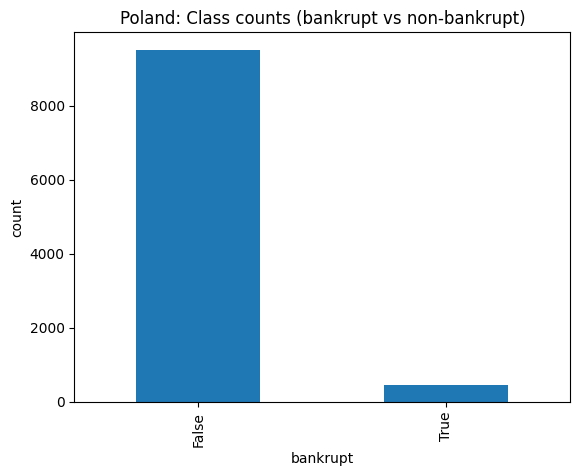

In [16]:
ax = target_counts.sort_index().plot(kind="bar")  # create `ax` for a bar chart from `target_counts`
ax.set_title("Poland: Class counts (bankrupt vs non-bankrupt)")  # change the ax title
ax.set_xlabel("bankrupt")  # change the ax x-axis label
ax.set_ylabel("count")  # change the ax y-axis label

In [17]:
assert target_counts.size == 2, (
    "Expected two classes in 'bankrupt'. "
    "Check your dataset and wrangling."
)
assert target_counts.min() > 0, "Both classes should have at least 1 example."
assert target_counts.max() / target_counts.min() > 1.5

5. Menyiapkan fitur dan target

- dropna() membuang semua baris yang punya NaN, sehingga data turun menjadi 4.658 baris. Ini perlu diperhatikan karena membuang banyak data.
- feature_cols mengambil kolom berawalan feat_ (64 fitur), y = kolom bankrupt dijadikan integer.

In [32]:
# drop NaN observations and make a copy of poland_df
poland_df_2 = poland_df.dropna().copy()

# select feature columns that starts with "feat_"
feature_cols = [feat for feat in poland_df_2.columns if feat.startswith("feat_")]

X = poland_df_2[feature_cols]
y = poland_df_2["bankrupt"].astype(int)  # also force the value as integer type.

X.shape, y.shape

((4658, 64), (4658,))

In [34]:
assert X.shape[1] == 64, "Poland should have feat_1..feat_64"
assert set(np.unique(y)).issubset({0, 1})

6. Train/test split

- train_test_split(test_size=0.2, random_state=42, stratify=y) menghasilkan train 3.726 dan test 932 baris.
- stratify=y menjaga proporsi kelas: rasio bangkrut train 2,20% vs test 2,15%.

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train.shape, X_test.shape

((3726, 64), (932, 64))

In [37]:
train_rate = y_train.mean()
test_rate = y_test.mean()

assert abs(train_rate - test_rate) < 0.01

train_rate, test_rate

(np.float64(0.02200751476113795), np.float64(0.02145922746781116))

7. Baseline DummyClassifier

- Strategi most_frequent selalu menebak “tidak bangkrut”.
- Hasil: akurasi 97,85%, tetapi precision, recall, F1 = 0. 
- Confusion matrix [[912,0],[20,0]]: 20 perusahaan bangkrut tidak terdeteksi sama sekali.

In [38]:
dummy = DummyClassifier(strategy="most_frequent")  # use DummyClassifier with most frequent strategy
# train the dummy model on X_train and y_train
dummy.fit(X_train, y_train)

y_pred_dummy = dummy.predict(X_test)

In [40]:
acc_dummy = accuracy_score(y_test, y_pred_dummy)
prec_dummy = precision_score(y_test, y_pred_dummy, zero_division=0)
rec_dummy = recall_score(y_test, y_pred_dummy, zero_division=0)
f1_dummy = f1_score(y_test, y_pred_dummy, zero_division=0)

acc_dummy, prec_dummy, rec_dummy, f1_dummy

(0.9785407725321889, 0.0, 0.0, 0.0)

In [41]:
# create a confusion matrix between y_test and y_pred_dummy
cm_dummy = confusion_matrix(y_test, y_pred_dummy)
cm_dummy

array([[912,   0],
       [ 20,   0]])

In [42]:
assert rec_dummy == 0.0

8. Logistic Regression (tanpa scaling)

- LogisticRegression(max_iter=1000, solver="lbfgs") di-fit, lalu predict dan predict_proba[:,1].
- Muncul ConvergenceWarning karena fitur belum diskalakan.
- Hasil: akurasi 97,42%, precision/recall/F1 = 0; ROC-AUC 0,621; PR-AUC 0,049. Confusion matrix [[908,4],[20,0]].
- classification_report menegaskan kelas 1 tidak terdeteksi.

In [43]:
# instantiate the logistic regression model with `max_iter=1000` and `solver="lbfgs"`
log_reg = LogisticRegression(
    max_iter=1000,
    solver="lbfgs",
)

log_reg.fit(X_train, y_train)  # train log_reg with X_train and y_train

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [44]:
# use log_reg to predict on X_test
y_pred_lr = log_reg.predict(X_test)
# use `log_reg` to predict probabilities on `X_test`, and select the
# probability of class 1 with `[:, 1]`
y_proba_lr = log_reg.predict_proba(X_test)[:, 1]

y_pred_lr[:5], y_proba_lr[:5]

(array([0, 0, 0, 0, 0]),
 array([0.00040297, 0.0072166 , 0.01390319, 0.00010556, 0.02266228]))

In [46]:
# compute metrics between `y_test` and `y_pred_lr`
acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr, zero_division=0)
rec_lr = recall_score(y_test, y_pred_lr, zero_division=0)
f1_lr = f1_score(y_test, y_pred_lr, zero_division=0)

acc_lr, prec_lr, rec_lr, f1_lr

(0.9742489270386266, 0.0, 0.0, 0.0)

In [47]:
# compute the confusion matrix between `y_test` and `y_pred_lr`
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_lr

array([[908,   4],
       [ 20,   0]])

In [48]:
# calculate ROC-AUC using `y_test` and `y_proba_lr`
roc_auc = roc_auc_score(y_test, y_proba_lr)
# calculate the average precision score using `y_test` and `y_proba_lr`
pr_auc = average_precision_score(y_test, y_proba_lr)

roc_auc, pr_auc

(0.6206140350877193, 0.049345845095748325)

In [50]:
# call the classification_report for `y_test`, `y_pred_lr`, `digits=3`
# and `zero_division=0`
classification_report(
    y_test,
    y_pred_lr,
    digits=3,
    zero_division=0,
)

'              precision    recall  f1-score   support\n\n           0      0.978     0.996     0.987       912\n           1      0.000     0.000     0.000        20\n\n    accuracy                          0.974       932\n   macro avg      0.489     0.498     0.493       932\nweighted avg      0.957     0.974     0.966       932\n'

In [51]:
assert (y_pred_lr != y_pred_dummy).any()

9. evaluate_binary_classifier()

- Fungsi pembungkus yang mengembalikan dict berisi accuracy, precision, recall, F1, ROC-AUC, dan PR-AUC.

In [52]:
def evaluate_binary_classifier(
    *,
    name: str,
    y_true: np.ndarray | pd.Series,
    y_pred: np.ndarray,
    y_proba: np.ndarray,
) -> dict[str, float | str]:
    """
    Compute key metrics for binary classification.

    Parameters
    ----------
    name
        Label for the model (used in the results table).
    y_true
        True labels (0/1).
    y_pred
        Predicted labels (0/1).
    y_proba
        Predicted probabilities for class 1.

    Returns
    -------
    dict of str to float | str
        Metrics: accuracy, precision, recall, f1, roc_auc, pr_auc.
    """
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "pr_auc": average_precision_score(y_true, y_proba),
    }

10. Perbandingan dengan/ tanpa scaling

- log_reg_plain (tanpa scaling) vs log_reg_scaled (Pipeline: MinMaxScaler lalu LogisticRegression).
- Hasil: ROC-AUC naik dari 0,621 ke 0,667, tetapi PR-AUC turun dari 0,049 ke 0,036. Precision/recall/F1 tetap 0 pada kedua model.
- assert memastikan panjang probabilitas sama dengan data uji dan semua nilainya finite.

In [53]:
log_reg_plain = LogisticRegression(
    max_iter=1000,
    solver="lbfgs",
)
log_reg_plain.fit(X_train, y_train)

y_pred_plain = log_reg_plain.predict(X_test)
y_proba_plain = log_reg_plain.predict_proba(X_test)[:, 1]

/usr/local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [54]:
# create a pipeline log_reg_scaled with 2 steps: MinMaxScaler as scaler and
# LogisticRegression as model (using the same parameters used in Code 5.2.9.2)
log_reg_scaled = Pipeline(
    steps=[
        ("scaler", MinMaxScaler()),
        ("model", LogisticRegression(max_iter=1000, solver="lbfgs")),
    ]
)
# train `log_reg_scaled` using `X_train` and `y_train`
log_reg_scaled.fit(X_train, y_train)

# generate predictions for `X_test` using `log_reg_scaled`
y_pred_scaled = log_reg_scaled.predict(X_test)
# predict probabilities for `X_test` using `log_reg_scaled`,
# and select the class 1 probabilities with `[:, 1]`
y_proba_scaled = log_reg_scaled.predict_proba(X_test)[:, 1]

In [55]:
rows = [
    evaluate_binary_classifier(
        name="LogReg (no scaling)",
        y_true=y_test,
        y_pred=y_pred_plain,
        y_proba=y_proba_plain,
    ),
    evaluate_binary_classifier(
        name="LogReg + MinMaxScaler",
        y_true=y_test,
        y_pred=y_pred_scaled,
        y_proba=y_proba_scaled,
    ),
]

results = pd.DataFrame(rows).set_index("model")
results

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
LogReg (no scaling),0.974249,0.0,0.0,0.0,0.620614,0.049346
LogReg + MinMaxScaler,0.978541,0.0,0.0,0.0,0.667434,0.035883


In [56]:
# generate the confusion matrix using `y_test` and `y_pred_plain`
cm_plain = confusion_matrix(y_test, y_pred_plain)
# generate the confusion matrix using `y_test` and `y_pred_scaled`
cm_scaled = confusion_matrix(y_test, y_pred_scaled)

cm_plain, cm_scaled

(array([[908,   4],
        [ 20,   0]]),
 array([[912,   0],
        [ 20,   0]]))

In [57]:
assert len(y_proba_plain) == len(y_test)
assert len(y_proba_scaled) == len(y_test)
assert np.isfinite(y_proba_plain).all()
assert np.isfinite(y_proba_scaled).all()

11. Kurva ROC dan Precision–Recall

- roc_curve memplot FPR vs TPR; precision_recall_curve memplot recall vs precision.
- Kurva PR lebih informatif untuk data yang sangat imbalanced.

Text(0, 0.5, 'True Positive Rate (TPR / Recall)')

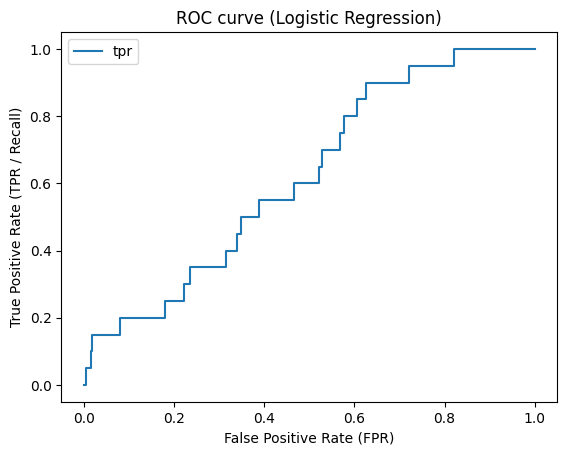

In [58]:
# compute the ROC curve from `y_test` and `y_proba_lr`
fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba_lr)

ax = pd.DataFrame({"fpr": fpr, "tpr": tpr}).plot(x="fpr", y="tpr")
ax.set_title("ROC curve (Logistic Regression)")
ax.set_xlabel("False Positive Rate (FPR)")
ax.set_ylabel("True Positive Rate (TPR / Recall)")

Text(0, 0.5, 'Precision')

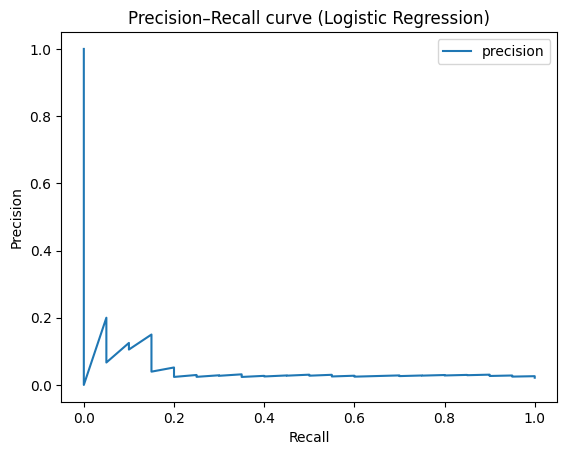

In [59]:
# compute the Precision–Recall curve from `y_test` and `y_proba_lr`
prec_curve, rec_curve, pr_thresholds = precision_recall_curve(
    y_test, y_proba_lr
)

ax = pd.DataFrame({"recall": rec_curve, "precision": prec_curve}).plot(
    x="recall",
    y="precision",
)
ax.set_title("Precision–Recall curve (Logistic Regression)")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")

12. Prevalence

- y_test.mean() = 0,0215, yaitu baseline PR-AUC jika menebak acak.

In [60]:
prevalence = float(y_test.mean())
prevalence

0.02145922746781116

13. Threshold tuning

- Threshold diubah dari default 0,5 ke 0,2 dan 0,1
- Menurunkan threshold mulai menangkap perusahaan bangkrut, tetapi hasilnya masih sangat lemah.

In [63]:
threshold = 0.5  # try 0.5, 0.2, 0.1 ...
y_pred_thr = (y_proba_lr >= threshold).astype(int)

precision_thr = precision_score(y_test, y_pred_thr, zero_division=0)
recall_thr = recall_score(y_test, y_pred_thr, zero_division=0)
f1_thr = f1_score(y_test, y_pred_thr, zero_division=0)

precision_thr, recall_thr, f1_thr

(0.0, 0.0, 0.0)

In [65]:
threshold = 0.1  # try 0.5, 0.2, 0.1 ...
y_pred_thr = (y_proba_lr >= threshold).astype(int)

precision_thr = precision_score(y_test, y_pred_thr, zero_division=0)
recall_thr = recall_score(y_test, y_pred_thr, zero_division=0)
f1_thr = f1_score(y_test, y_pred_thr, zero_division=0)

precision_thr, recall_thr, f1_thr

(0.09090909090909091, 0.05, 0.06451612903225806)

In [66]:
threshold = 0.2  # try 0.5, 0.2, 0.1 ...
y_pred_thr = (y_proba_lr >= threshold).astype(int)

precision_thr = precision_score(y_test, y_pred_thr, zero_division=0)
recall_thr = recall_score(y_test, y_pred_thr, zero_division=0)
f1_thr = f1_score(y_test, y_pred_thr, zero_division=0)

precision_thr, recall_thr, f1_thr

(0.2, 0.05, 0.08)

In [67]:
# Lowering threshold often increases recall (but may reduce precision).
assert y_pred_thr.shape == y_test.shape
assert set(np.unique(y_pred_thr)).issubset({0, 1})
assert 0.0 <= precision_thr <= 1.0
assert 0.0 <= recall_thr <= 1.0
assert 0.0 <= f1_thr <= 1.0

Kesimpulan Singkat

- Akurasi menyesatkan. 
- Dummy classifier mendapat akurasi 97,85% tanpa mendeteksi satu pun perusahaan bangkrut. 
- Untuk data imbalanced (bangkrut hanya ~2-5%), gunakan recall, precision, F1, dan PR-AUC.
- Logistic Regression default gagal mendeteksi kelas bangkrut (recall = 0 pada threshold 0,5). 
- ROC-AUC ~0,62-0,67 hanya sedikit di atas acak, dan PR-AUC (0,04-0,05) hanya sedikit di atas prevalence (0,021).
- Scaling membantu sebagian. 
- MinMaxScaler menaikkan ROC-AUC, tetapi tidak memperbaiki recall dan PR-AUC-nya malah turun, jadi tidak cukup sebagai solusi.
- Menurunkan threshold (0,2 atau 0,1) meningkatkan recall dari 0 menjadi 0,05 dengan precision 0,09-0,20. 
- Ini langkah yang benar arahnya, tetapi performa masih rendah.

Catatan kualitas data: dropna() membuang sekitar separuh data (9.977 menjadi 4.658) dan hanya menyisakan 20 kasus bangkrut di test set, sehingga metrik sangat tidak stabil.

Langkah lanjutan yang disarankan: imputasi nilai hilang (bukan dropna), class_weight="balanced" atau SMOTE, model non-linear (Random Forest, Gradient Boosting), cross-validation, serta pemilihan threshold berdasarkan kurva PR.